# Stroke lesion segmentation with multimodal MRI
## An ISLES 2022 medical AI portfolio study

**Question:** How well can a small 3D U-Net delineate expert-annotated ischemic stroke lesions from DWI, ADC, and FLAIR MRI?

This project follows a complete research experiment: inspect native MRI geometry, prepare three-channel volumes, sample training patches, train a MONAI U-Net, choose settings on validation patients, and examine patient-level internal test performance. The most informative findings include small-lesion failures as well as successful segmentations.

**Status:** This is the refactored portfolio notebook. Its executable code has **not been run on the MRI dataset** and has no saved execution outputs. Historical evidence below is separately labeled and comes from the unchanged original experiment; it does not verify this refactor's performance.

[Open this companion in Google Colab](https://colab.research.google.com/github/sbmedtech/isles2022-stroke-mri-segmentation/blob/main/notebooks/ISLES_2022_Portfolio.ipynb) · [Historical reference](https://github.com/sbmedtech/isles2022-stroke-mri-segmentation/blob/e507752a5095bf287e5a7291f819e3a0d0c72135/ISLES_2022_First_Colab_Notebook.ipynb) · [Execution guide](https://github.com/sbmedtech/isles2022-stroke-mri-segmentation/blob/main/notebooks/PORTFOLIO_GUIDE.md)

### Clinical context and imaging inputs

DWI highlights restricted diffusion, ADC provides complementary diffusion information, and FLAIR provides structural signal. The learning task is **lesion delineation**, using the supplied expert mask as the reference. A segmentation score alone does not establish diagnostic accuracy, treatment eligibility, or clinical readiness.

The public ISLES 2022 dataset contains **250 expert-annotated cases**. The MRI sequences are supplied in native spaces. Here DWI is the reference grid; FLAIR is resampled using its existing affine. This is not independently estimated anatomical registration.

### Experiment at a glance

| Component | Existing implementation |
|---|---|
| Inputs | DWI, ADC, FLAIR, in that channel order |
| Network | MONAI 3D U-Net; channels `(16, 32, 64, 128)`, two residual units; 1,187,546 parameters |
| Patient split | 175 training / 37 validation / 38 internal test; seed 42 |
| Training samples | Paired image/mask patches of `(64, 64, 32)` voxels |
| Optimization | Dice + cross-entropy; AdamW, learning rate `1e-4`, weight decay `1e-5` |
| Schedule | 3 initial epochs; continuation to 23, then 43 |
| Evaluation | Full-volume patient Dice; validation-selected threshold and checkpoint |

```text
DWI + ADC + FLAIR → grid checks and normalization → three-channel volume
                 → training patches → 3D U-Net → full-volume lesion mask
                 → patient-level overlap and failure analysis
```

### Historical results: preserved, not newly verified

| Saved evaluation | Lesion-positive patients | Mean Dice | Median Dice | Empty predictions |
|---|---:|---:|---:|---:|
| Epoch-23 validation, threshold 0.25 | 36 of 37 | 0.5219 | 0.6230 | 2 |
| Best recorded validation, epoch 43, threshold 0.25 | 36 of 37 | 0.5991 | 0.6578 | 1 |
| Internal test, epoch 43, threshold 0.25 | 37 of 38 | 0.5377 | 0.5818 | 2 |

These figures reproduce the **saved notebook record**, not a new experimental run. Primary summaries exclude expert-empty patients; those cases are assessed separately for false positives. The 38-case partition is an internal split of the public dataset, not the hidden ISLES challenge test set. Historical checkpoint and threshold lineage remain a separate evidence-review question.

### How to navigate

Use Colab's table of contents or the section headings below. The sections below follow setup → data → preprocessing → model → staged training → validation → frozen evaluation. Module responsibilities and verification limits appear at the end.

**Before executing:** Reading this study requires no code execution. Download, training, and evaluation switches default to **False**. Change them only for a deliberate experiment with the required data/artifacts, not to view historical figures.


## 1. Install the local package in Colab or Jupyter

The notebook is an orchestration layer; scientific functions live in `isles2022/`. In Colab, this setup clones the repository and installs the notebook dependencies. Locally, run from the repository root or `notebooks/` directory. Before this PR merges, reviewers should install their checked-out PR revision rather than `main`.

No training or dataset inference occurs during setup. Reading Markdown and historical assets needs no setup execution.


In [ ]:
from pathlib import Path
import importlib.util
import subprocess
import sys

IN_COLAB = importlib.util.find_spec("google") is not None and importlib.util.find_spec("google.colab") is not None
REPO_DIR = Path("/content/isles2022-stroke-mri-segmentation") if IN_COLAB else Path.cwd()
if not IN_COLAB and REPO_DIR.name == "notebooks":
    REPO_DIR = REPO_DIR.parent
if IN_COLAB and not (REPO_DIR / "pyproject.toml").exists():
    subprocess.run(["git", "clone", "https://github.com/sbmedtech/isles2022-stroke-mri-segmentation.git", str(REPO_DIR)], check=True)
if not (REPO_DIR / "pyproject.toml").exists():
    raise FileNotFoundError("Run from a repository checkout or its notebooks directory.")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", f"{REPO_DIR}[notebook]"], check=True)


## 2. One configuration and explicit execution switches

Paths are declared once. Use a fresh Drive project and local cache for a new experiment; existing cache files are reused by existence. The configuration contains the original seed, patches, batch size, loss/optimizer settings and stage boundaries—no tuning was introduced.

The code retains the original seed calls. Diagnostic draws and reordered inspection steps mean exact historical scratch-run RNG replay is not established. Checkpoints do not restore all RNG state. None of the switches were enabled or executed to produce this refactor.


In [ ]:
from functools import partial
import torch

from isles2022.config import ExperimentConfig, ProjectPaths
from isles2022.data import download_dataset, extract_dataset, load_or_create_splits
from isles2022.preprocessing import preprocess_patient
from isles2022.datasets import cache_patients, load_cached_patient, training_loader
from isles2022.training import (
    seed_reference_rng, training_components, diagnostic_optimizer_step,
    train_until, persist_validation_threshold, train_with_validation,
)
from isles2022.checkpoints import load_checkpoint, load_selected_checkpoint
from isles2022.evaluation import select_threshold, evaluate_patients
from isles2022.metrics import summarize_patient_metrics
from isles2022.provenance import selection_context, artifact_provenance, save_test_artifact
from isles2022.visualization import plot_training_history, plot_test_examples, plot_lesion_size, write_test_pdf

config = ExperimentConfig()
paths = ProjectPaths(Path("/content/drive/MyDrive/ISLES2022_Portfolio_Run"),
                     Path("/content/isles2022_portfolio_cache"))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PREPARE_DATA = False
RUN_TRAINING = False
RUN_EVALUATION = False
seed_reference_rng(config.seed)


## 3. Official data and the fixed patient partition

`download_dataset` streams the official Zenodo archive and preserves the existing byte-size verification. It is not a cryptographic checksum check. `load_or_create_splits` uses sorted patient IDs, seed 42 and **175/37/38**, and rejects a differing saved split. This remains an internal partition of the public dataset.

For evaluation-only use with an existing dataset, enable `PREPARE_DATA`; a complete archive is reused. A local runtime needs a project path that actually exists on that machine.


In [ ]:
splits = None
if PREPARE_DATA:
    if IN_COLAB:
        from google.colab import drive
        drive.mount("/content/drive")
    paths.create()
    archive = download_dataset(paths.data)
    extract_dataset(archive, paths.data / "extracted")
    splits = load_or_create_splits(paths.dataset, paths.splits, config.seed)
    print({name: len(splits[name]) for name in ("train", "validation", "test")})


## 4. Preprocess one case, then cache only training/validation data

`preprocess_patient` requires ADC and mask shape/affine agreement with DWI, resamples FLAIR with linear interpolation, normalizes nonzero finite voxels independently, and stacks **DWI → ADC → FLAIR**. It requires expert labels for this research workflow. It does not estimate registration or change voxel spacing.

`CachedPatchDataset` alternates lesion-centered and random paired crops. Random crops can contain lesions, and expert-empty masks fall back to random sampling. Padding/crop/random-draw parity is tested directly against the original notebook.


In [ ]:
if PREPARE_DATA:
    image, label = preprocess_patient(splits["train"][0], paths.dataset)
    print({"image_shape": tuple(image.shape), "label_shape": tuple(label.shape)})
    cache_patients(splits["train"] + splits["validation"], paths.dataset, paths.cache)


## 5. Initialize the reference model and make the diagnostic update explicit

The existing raw MONAI factory preserves architecture/defaults and state-dict names. `training_components` constructs the same DiceCELoss and AdamW. The original notebook's pre-epoch optimizer diagnostic is retained as a clearly named **weight-changing** function, called once for a fresh training run. It is not a neutral forward check and must not be repeated after restoring a checkpoint.


In [ ]:
if RUN_TRAINING:
    if splits is None:
        raise RuntimeError("Prepare the dataset and split before training.")
    model, loss_function, optimizer = training_components(device, config)
    initial_loader = training_loader(splits["train"], paths.cache, config.initial_patches, config, device)
    extended_loader = training_loader(splits["train"], paths.cache, config.extended_patches, config, device)
    diagnostic_loss = diagnostic_optimizer_step(model, optimizer, loss_function, next(iter(initial_loader)), device)
    print({"diagnostic_loss": diagnostic_loss})


## 6. Train through epochs 3 and 23 using one shared epoch function

The first stage uses two patches per patient. Continuation uses four, preserving batch size 2, loss, optimizer and epoch targets. `train_until` restores supplied model/optimizer state and writes the original four-key checkpoint schema; it does not reconstruct the model inside a training loop.

These calls are for a **new deliberate experiment**. They have not been executed here. Initial training can overwrite an existing latest checkpoint: use a separate project. Full MRI training/Colab behavior remains unverified.


In [ ]:
if RUN_TRAINING:
    checkpoint = train_until(model, optimizer, loss_function, initial_loader, device, paths,
                             config.initial_epochs)
    checkpoint = train_until(model, optimizer, loss_function, extended_loader, device, paths,
                             config.selection_epoch, checkpoint=checkpoint)
    plot_training_history(checkpoint["training_history"])


### Historical training plot — unchanged artifact, not refactor output

The plot below is the exact PNG saved in original notebook cell 40 for the historical continuation through epoch 23. It has not been recomputed, and it does not demonstrate execution of the code above.


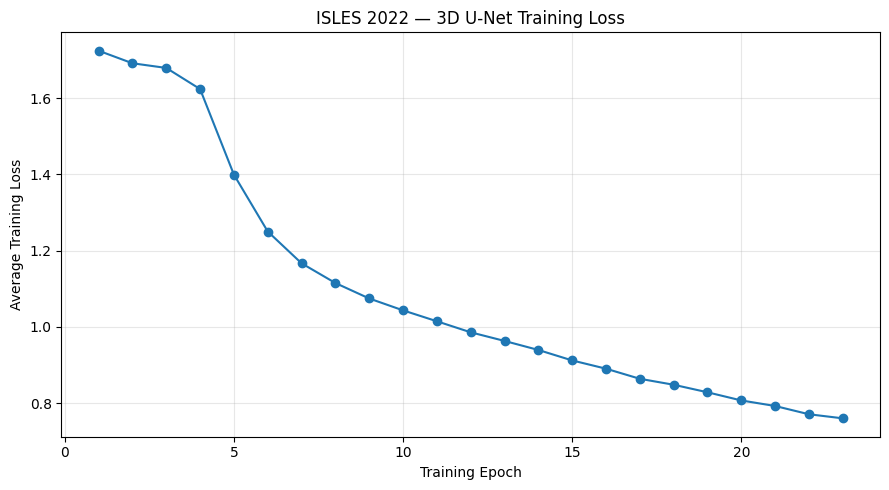

Source: [original experiment at the reviewed baseline](https://github.com/sbmedtech/isles2022-stroke-mri-segmentation/blob/e507752a5095bf287e5a7291f819e3a0d0c72135/ISLES_2022_First_Colab_Notebook.ipynb).


## 7. Select a threshold on validation patients only

The validation sweep evaluates **0.05–0.50** and selects lesion-positive mean Dice. The historical value was **0.25**; fresh execution uses its measured threshold rather than a hard-coded fallback. Threshold selection is bound to the exact restored epoch-23 weights.

The original early inspection prints and repeated single-case threshold diagnostics are no longer executable notebook clutter; the complete historical record remains in the unchanged original notebook/Git history.


In [ ]:
if RUN_TRAINING:
    validation_reader = partial(load_cached_patient, cache_dir=paths.cache)
    threshold, threshold_details, threshold_summary = select_threshold(
        model, splits["validation"], validation_reader, device, config)
    persist_validation_threshold(paths.models / "checkpoint_latest.pt", model, threshold)
    threshold_details.to_csv(paths.results / "validation_threshold_details.csv", index=False)
    threshold_summary.to_csv(paths.results / "validation_threshold_summary.csv", index=False)
    display(threshold_summary)


## 8. Continue to epoch 43 and select measured best weights

Validation remains every five epochs after 23: **28, 33, 38, 43**. Baseline and best weights are measured rather than compared with historical scores. Canonical optimizer metadata, weight/context/run checks and strict greater-than selection are preserved.

Source-code fingerprints now identify extracted modules. Raw model/optimizer dictionaries remain load-compatible, but older selection contexts are not silently relabeled as module-era experiments. Best/latest interruption recovery and deterministic RNG restoration were not redesigned.


In [ ]:
if RUN_TRAINING:
    load_checkpoint(paths.models / "checkpoint_latest.pt", model, optimizer, device)
    context = selection_context(paths, splits, model, optimizer, loss_function, config)
    checkpoint, validation_history = train_with_validation(
        model, optimizer, loss_function, extended_loader, device, paths, splits, context, config)
    display(validation_history)


## 9. Evaluate a frozen checkpoint on the internal test cohort

This path does not train or tune. It validates the exact best checkpoint before applying weights or its threshold, reads labels for metrics, computes full-volume Dice, and exports the same provenance-bound schema. Expert-empty patients remain separate from the primary mean/median.

Evaluation requires the actual MRI data and matching verified configuration/cache/selection artifacts. Legacy weights alone do not establish threshold or experiment lineage; no missing threshold is invented. The refactor and its synthetic tests do not reproduce historical MRI performance.

The repository also provides [model-v0.1.0-preview](https://github.com/sbmedtech/isles2022-stroke-mri-segmentation/releases/tag/model-v0.1.0-preview), whose raw model state has been independently checked for architecture compatibility. That four-key legacy checkpoint has no validation threshold or selection context. It cannot enter this strict evaluation path as a provenance-verified selection; do not fabricate fields or substitute a threshold. Compatibility does not establish historical performance or lineage. See the README for download/checksum and direct model-loading guidance.


In [ ]:
if RUN_EVALUATION:
    if splits is None:
        raise RuntimeError("Prepare the dataset and matching saved split before evaluation.")
    model, loss_function, optimizer = training_components(device, config)
    latest = load_checkpoint(paths.models / "checkpoint_latest.pt", model, optimizer, device)
    context = selection_context(paths, splits, model, optimizer, loss_function, config)
    run_id = latest["selection"]["run_id"]
    selected, threshold = load_selected_checkpoint(
        paths.models / "checkpoint_best_validation.pt", model, context, run_id, device)
    test_reader = partial(preprocess_patient, dataset_dir=paths.dataset)
    test_results = evaluate_patients(model, splits["test"], test_reader, threshold, device, config)
    provenance = artifact_provenance(selected, context, run_id, splits["test"])
    test_csv = save_test_artifact(test_results, paths.root, provenance)
    print(summarize_patient_metrics(test_results.to_dict("records")))


## 10. Current figures use matching metrics; historical figures stay separate

Fresh plots/PDFs recompute masks and check their counts/Dice against the exact CSV identity before publication. The lesion-size analysis remains descriptive **voxel count** versus Dice, not physical mL. Example slices use expert lesion area; patient Dice is full-volume.

The calls below are disabled with evaluation. They do not regenerate or replace the historical gallery. No new MRI image was generated during this refactor.


In [ ]:
if RUN_EVALUATION:
    plot_test_examples(model, selected, context, run_id,
                       ["sub-strokecase0237", "sub-strokecase0115"], test_reader, device, config, paths.root)
    plot_lesion_size(selected, context, run_id, paths.root)
    pdf_path = write_test_pdf(model, selected, context, run_id, test_reader, device, config, paths.root)
    print({"test_csv": str(test_csv), "patient_pdf": str(pdf_path)})


### Historical MRI examples — genuine saved evidence

![Historical DWI, expert masks and predictions for cases 0237 and 0115](https://raw.githubusercontent.com/sbmedtech/isles2022-stroke-mri-segmentation/e507752a5095bf287e5a7291f819e3a0d0c72135/assets/portfolio/historical-test-examples.png)

This unchanged, previously reviewed asset was extracted from original cell 47: case 0237 has historical full-volume Dice **0.869**; case 0115 is a small-lesion miss with **0.000**. Panels show normalized DWI, expert mask and prediction, rotated identically for display. The selected slice maximizes expert lesion area. These illustrative cases are not the entire test distribution or new refactor predictions.

Credit: Hernandez Petzsche et al., ISLES 2022, Scientific Data (2022), [DOI](https://doi.org/10.1038/s41597-022-01875-5), [Zenodo](https://zenodo.org/records/7960856), CC BY 4.0 for dataset-derived figures. [Figure source/evidence notes](../docs/portfolio/figures-and-results.md). Software licensing is separate from images and model weights.


## 11. What moved into reusable Python

| Module | Responsibility |
|---|---|
| `config.py` | Project paths and unchanged experiment/model settings |
| `data.py` | Official archive, patient discovery, split persistence |
| `preprocessing.py` | DWI-grid channel/label loading and normalization |
| `datasets.py` | Disk cache, paired patch sampling, loader construction |
| `model.py` | Existing raw MONAI U-Net factory |
| `training.py` | Explicit diagnostic update, shared epoch/stage functions, measured validation continuation |
| `evaluation.py` / `metrics.py` | Shared probabilities, validation threshold sweep, full-volume patient metrics |
| `checkpoints.py` / `provenance.py` | Strict loading and canonical checkpoint/artifact identity |
| `visualization.py` | Checked example plots, size analysis, patient PDF |

The notebook now declares inputs and calls named functions. It does not define a training framework or CLI. All changed code outputs are empty, and the historical table/figures are independent Markdown artifacts.

### Verification limits

Synthetic tests compare extracted normalization, spatial preprocessing, patch draws/crops, splits, training updates, inference/threshold logic and identity behavior with the unchanged reference. They check raw checkpoint compatibility and stale artifact rejection. They do not establish full-dataset numerical parity, historical RNG replay, actual legacy threshold lineage, MRI alignment, GPU/Colab execution or clinical validity. Affine resampling is not registration. No retraining, tuning or historical-result changes were performed.

The original experiment remains unchanged in the current tree and Git history. Its future public-file-listing treatment belongs to Agent 3 after the owner's explicit backup/listing confirmation.
